# 1. Exploratory Data Analysis: Big Black Money Transactions

This notebook explores `Big_Black_Money_Dataset.csv` to understand its structure, data quality, transaction patterns, and possible preparation steps for later analysis or modeling. The analysis is descriptive: it does not establish that a transaction is actually illicit, nor does it assume which field should be the final prediction target.

## Table of Contents

- [1.1 Introduction](#11-introduction)
- [1.2 Preparation](#12-preparation)
- [1.3 Dataset Summary](#13-dataset-summary)
- [1.4 Missing Values and Duplicates](#14-missing-values-and-duplicates)
- [1.5 Univariate Analysis](#15-univariate-analysis)
- [1.6 Temporal Analysis](#16-temporal-analysis)
- [1.7 Bivariate Analysis](#17-bivariate-analysis)
- [1.8 Feature Engineering](#18-feature-engineering)
- [1.9 Preprocessing Recommendations](#19-preprocessing-recommendations)
- [1.10 Final Insights](#110-final-insights)

## 1.1 Introduction

The dataset contains transaction-level records with amounts, dates, countries, transaction types, industries, financial institutions, and several fields related to reporting and money-laundering risk. The goal is to inspect these variables, identify data-quality concerns, and document preprocessing options before any modeling decisions are made.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

DATASET_NAME = "Big_Black_Money_Dataset.csv"
possible_paths = [
    Path(DATASET_NAME),
    Path("2ndProject") / DATASET_NAME,
]
dataset_path = next((path for path in possible_paths if path.exists()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f"Could not find {DATASET_NAME}. Place it beside this notebook "
        "or run the notebook from the repository root."
    )

raw_data = pd.read_csv(dataset_path)
data = raw_data.copy()

# Convert fields that should be numeric or temporal for reliable analysis.
for column in ["Amount (USD)", "Money Laundering Risk Score", "Shell Companies Involved"]:
    data[column] = pd.to_numeric(data[column], errors="coerce")

data["Date of Transaction"] = pd.to_datetime(
    data["Date of Transaction"], errors="coerce"
)
data["Reported by Authority"] = (
    data["Reported by Authority"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"true": True, "false": False})
)

print(f"Loaded {len(data):,} transactions from {dataset_path.resolve()}")
print(f"Dataset shape: {data.shape[0]:,} rows x {data.shape[1]} columns")

Loaded 10,000 transactions from C:\Users\maria\Documents\Universidade\Capstone\Capstone-Project\2ndProject\Big_Black_Money_Dataset.csv
Dataset shape: 10,000 rows x 14 columns


## 1.2 Preparation

The dataset is loaded from the same folder as this notebook when possible, with a repository-root fallback. A copy named `data` is used for exploration, while `raw_data` remains available as the untouched import. Date, numeric, and Boolean-like fields are parsed explicitly so later summaries and plots use the intended types.

## 1.3 Dataset Summary

### 1.3.1 Initial Preview and Structure

In [2]:
display(data.head())
print("\nDataset information:")
data.info()

print("\nNumerical descriptive statistics:")
display(data.describe(include=[np.number]).T)

print("\nCategorical descriptive statistics:")
display(data.describe(include=["object", "string", "bool"]).T)

,Transaction ID,Country,Amount (USD),Transaction Type,Date of Transaction,Person Involved,Industry,Destination Country,Reported by Authority,Source of Money,Money Laundering Risk Score,Shell Companies Involved,Financial Institution,Tax Haven Country
0,TX0000000001,Brazil,3.267530e+06,Offshore Transfer,2013-01-01 00:00:00,Person_1101,Construction,USA,True,Illegal,6,1,Bank_40,Singapore
1,TX0000000002,China,4.965767e+06,Stocks Transfer,2013-01-01 01:00:00,Person_7484,Luxury Goods,South Africa,False,Illegal,9,0,Bank_461,Bahamas
2,TX0000000003,UK,9.416750e+04,Stocks Transfer,2013-01-01 02:00:00,Person_3655,Construction,Switzerland,True,Illegal,1,3,Bank_387,Switzerland
3,TX0000000004,UAE,3.864201e+05,Cash Withdrawal,2013-01-01 03:00:00,Person_3226,Oil & Gas,Russia,False,Illegal,7,2,Bank_353,Panama
4,TX0000000005,South Africa,6.433784e+05,Cryptocurrency,2013-01-01 04:00:00,Person_7975,Real Estate,USA,True,Illegal,1,9,Bank_57,Luxembourg



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Transaction ID               10000 non-null  object        
 1   Country                      10000 non-null  object        
 2   Amount (USD)                 10000 non-null  float64       
 3   Transaction Type             10000 non-null  object        
 4   Date of Transaction          10000 non-null  datetime64[ns]
 5   Person Involved              10000 non-null  object        
 6   Industry                     10000 non-null  object        
 7   Destination Country          10000 non-null  object        
 8   Reported by Authority        10000 non-null  bool          
 9   Source of Money              10000 non-null  object        
 10  Money Laundering Risk Score  10000 non-null  int64         
 11  Shell Companies Invo

,count,mean,std,min,25%,50%,75%,max
Amount (USD),10000.0,2.501818e+06,1.424364e+06,10031.79673,1.279005e+06,2.501310e+06,3.722416e+06,4.999812e+06
Money Laundering Risk Score,10000.0,5.526400e+00,2.893603e+00,1.00000,3.000000e+00,6.000000e+00,8.000000e+00,1.000000e+01
Shell Companies Involved,10000.0,4.469400e+00,2.879773e+00,0.00000,2.000000e+00,4.000000e+00,7.000000e+00,9.000000e+00



Categorical descriptive statistics:


,count,unique,top,freq
Transaction ID,10000,10000,TX0000000001,1
Country,10000,10,China,1038
Transaction Type,10000,5,Property Purchase,2086
Person Involved,10000,6320,Person_7230,7
Industry,10000,7,Finance,1475
Destination Country,10000,10,USA,1061
Reported by Authority,10000,2,False,7995
Source of Money,10000,2,Illegal,7017
Financial Institution,10000,499,Bank_81,36
Tax Haven Country,10000,6,Panama,1743


## 1.4 Missing Values and Duplicates

Missingness and repeated records can affect both descriptive results and model evaluation. The checks below inspect nulls after type conversion, exact duplicate rows, and repeated transaction IDs. A repeated ID is not automatically removed: first determine whether it represents a duplicate or a legitimate correction/event.

In [3]:
missing_summary = pd.DataFrame({
    "Missing values": data.isna().sum(),
    "Missing percentage": (data.isna().mean() * 100).round(2),
}).sort_values("Missing percentage", ascending=False)

display(missing_summary)
print(f"Exact duplicate rows: {data.duplicated().sum():,}")
print(f"Duplicate transaction IDs: {data['Transaction ID'].duplicated().sum():,}")
print("\nUnique values per column:")
display(data.nunique(dropna=False).sort_values(ascending=False).to_frame("Unique values"))

,Missing values,Missing percentage
Transaction ID,0,0.0
Country,0,0.0
Amount (USD),0,0.0
Transaction Type,0,0.0
Date of Transaction,0,0.0
Person Involved,0,0.0
Industry,0,0.0
Destination Country,0,0.0
Reported by Authority,0,0.0
Source of Money,0,0.0


Exact duplicate rows: 0
Duplicate transaction IDs: 0

Unique values per column:


,Unique values
Transaction ID,10000
Amount (USD),10000
Date of Transaction,10000
Person Involved,6320
Financial Institution,499
Country,10
Destination Country,10
Money Laundering Risk Score,10
Shell Companies Involved,10
Industry,7


## 1.5 Univariate Analysis

### 1.5.1 Numerical Variables

Transaction amounts may be strongly right-skewed, so the amount plot uses a logarithmic axis when all observed values are positive. The risk score is shown as a discrete distribution; its meaning and suitability as a target must be confirmed from the dataset documentation.

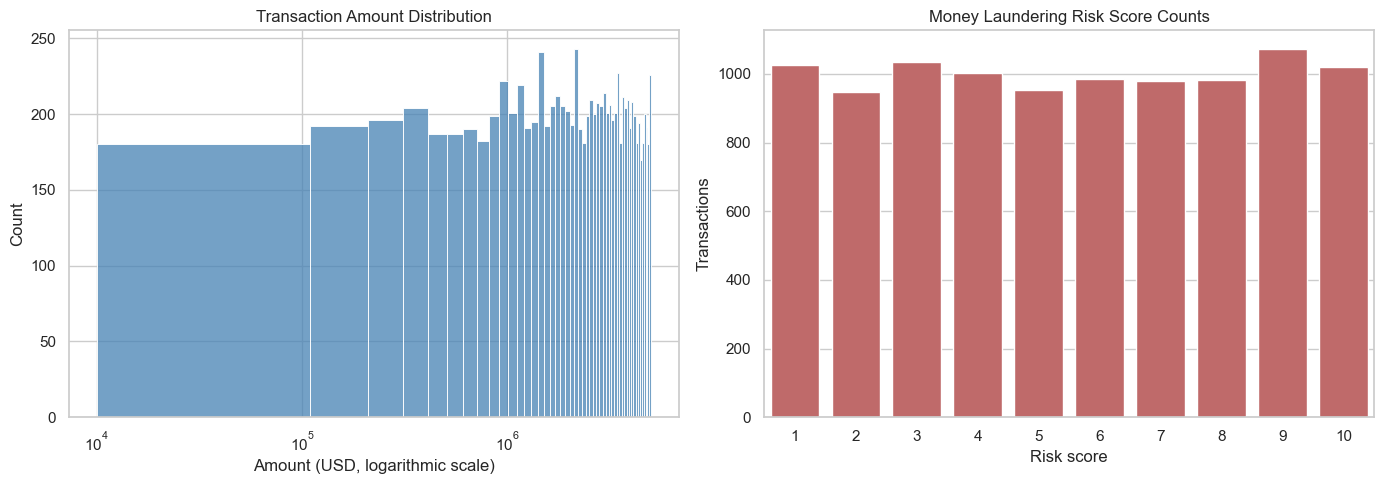

,count,mean,std,min,25%,50%,75%,max
Amount (USD),10000.0,2.501818e+06,1.424364e+06,10031.79673,1.279005e+06,2.501310e+06,3.722416e+06,4.999812e+06
Money Laundering Risk Score,10000.0,5.526400e+00,2.893603e+00,1.00000,3.000000e+00,6.000000e+00,8.000000e+00,1.000000e+01
Shell Companies Involved,10000.0,4.469400e+00,2.879773e+00,0.00000,2.000000e+00,4.000000e+00,7.000000e+00,9.000000e+00


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

amount_values = data["Amount (USD)"].dropna()
sns.histplot(amount_values, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Transaction Amount Distribution")
axes[0].set_xlabel("Amount (USD)")
if not amount_values.empty and (amount_values > 0).all():
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Amount (USD, logarithmic scale)")

sns.countplot(data=data, x="Money Laundering Risk Score", ax=axes[1], color="indianred")
axes[1].set_title("Money Laundering Risk Score Counts")
axes[1].set_xlabel("Risk score")
axes[1].set_ylabel("Transactions")
plt.tight_layout()
plt.show()

display(data[["Amount (USD)", "Money Laundering Risk Score", "Shell Companies Involved"]].describe().T)

### 1.5.2 Categorical Variables

The plots show the most frequent values for selected categorical features. These frequency counts help identify dominant categories and high-cardinality fields that may need special encoding.

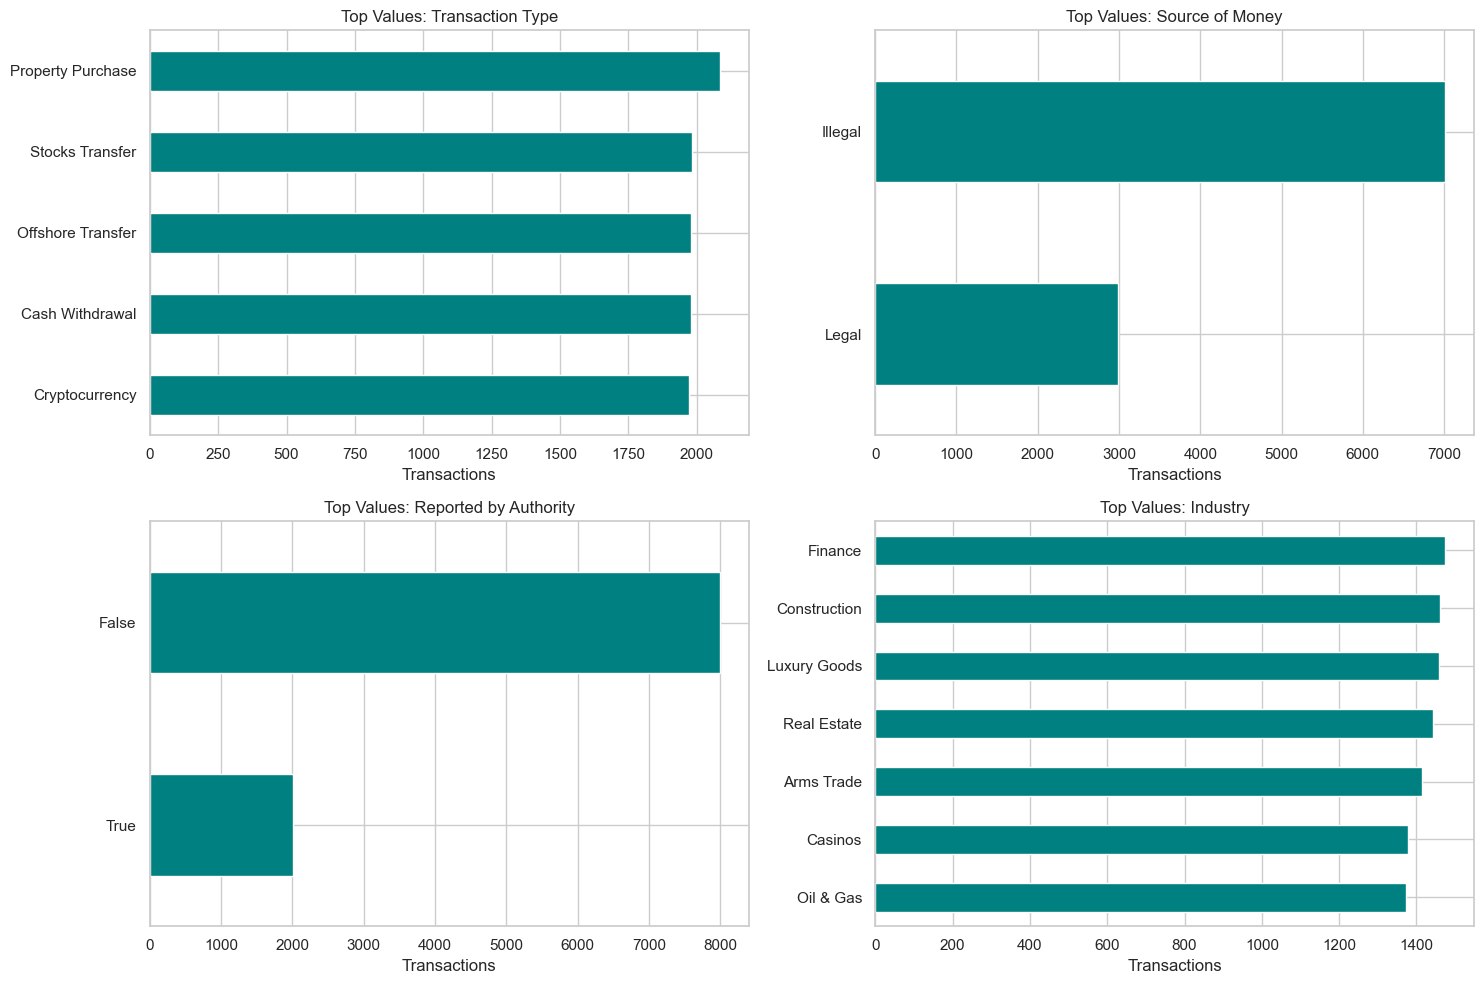

In [5]:
categorical_columns = [
    "Transaction Type",
    "Source of Money",
    "Reported by Authority",
    "Industry",
]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, axis in zip(categorical_columns, axes.flat):
    counts = data[column].astype("string").fillna("Missing").value_counts().head(10)
    counts.sort_values().plot(kind="barh", ax=axis, color="teal")
    axis.set_title(f"Top Values: {column}")
    axis.set_xlabel("Transactions")
    axis.set_ylabel("")

plt.tight_layout()
plt.show()

## 1.6 Temporal Analysis

Transaction timestamps can reveal changes in activity over time. The chart aggregates transaction counts by month; gaps or peaks should be checked against the dataset's collection process before being interpreted as real-world events.

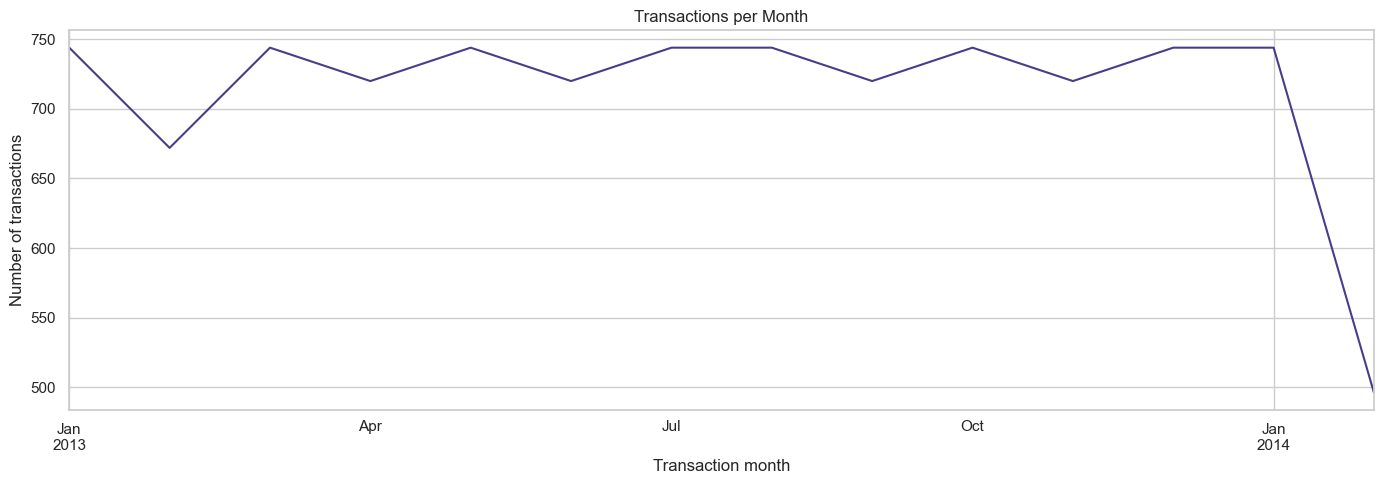

Rows with an invalid or missing transaction date: 0


In [6]:
dated_data = data.dropna(subset=["Date of Transaction"]).set_index("Date of Transaction")
monthly_counts = dated_data.resample("MS").size()

ax = monthly_counts.plot(figsize=(14, 5), color="darkslateblue")
ax.set_title("Transactions per Month")
ax.set_xlabel("Transaction month")
ax.set_ylabel("Number of transactions")
plt.tight_layout()
plt.show()

print(f"Rows with an invalid or missing transaction date: {data['Date of Transaction'].isna().sum():,}")

## 1.7 Bivariate Analysis

### 1.7.1 Numeric Relationships

A rank-based correlation is included because monetary values can be skewed and relationships may not be linear. Correlation is descriptive and does not imply causation.

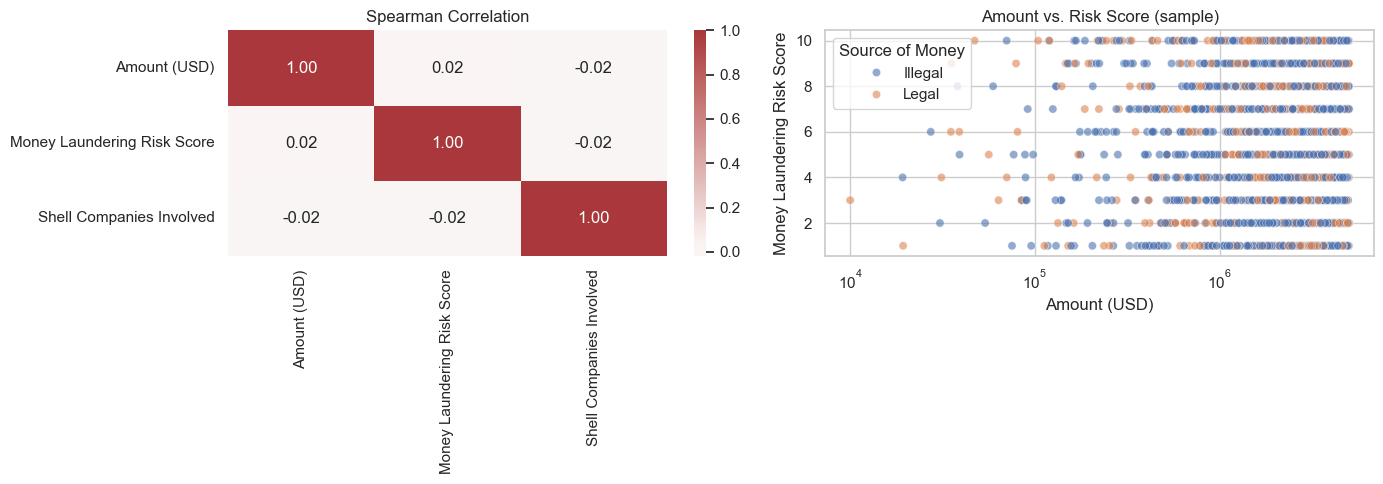

In [7]:
numeric_features = [
    "Amount (USD)",
    "Money Laundering Risk Score",
    "Shell Companies Involved",
]
correlation = data[numeric_features].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(correlation, annot=True, cmap="vlag", center=0, fmt=".2f", ax=axes[0])
axes[0].set_title("Spearman Correlation")

plot_sample = data[["Amount (USD)", "Money Laundering Risk Score", "Source of Money"]].dropna()
plot_sample = plot_sample.sample(min(2_000, len(plot_sample)), random_state=42)
sns.scatterplot(
    data=plot_sample,
    x="Amount (USD)",
    y="Money Laundering Risk Score",
    hue="Source of Money",
    alpha=0.6,
    ax=axes[1],
)
axes[1].set_title("Amount vs. Risk Score (sample)")
if not plot_sample.empty and (plot_sample["Amount (USD)"] > 0).all():
    axes[1].set_xscale("log")
plt.tight_layout()
plt.show()

## 1.8 Feature Engineering

The following derived fields are examples for exploration, not a final modeling dataset. The original columns remain unchanged, and any derived amount transformation is created only for non-negative values.

In [8]:
eda_features = data.copy()
transaction_dates = eda_features["Date of Transaction"]
eda_features["Transaction Year"] = transaction_dates.dt.year
eda_features["Transaction Month"] = transaction_dates.dt.month
eda_features["Transaction Day of Week"] = transaction_dates.dt.dayofweek
eda_features["Is Cross-Border"] = (
    eda_features["Country"].str.strip().str.casefold()
    != eda_features["Destination Country"].str.strip().str.casefold()
)

eda_features["Amount Log1p"] = np.nan
non_negative_amounts = eda_features["Amount (USD)"].ge(0)
eda_features.loc[non_negative_amounts, "Amount Log1p"] = np.log1p(
    eda_features.loc[non_negative_amounts, "Amount (USD)"]
)

display(eda_features[[
    "Date of Transaction",
    "Transaction Year",
    "Transaction Month",
    "Transaction Day of Week",
    "Country",
    "Destination Country",
    "Is Cross-Border",
    "Amount (USD)",
    "Amount Log1p",
]].head())
print(f"Negative amount records: {data['Amount (USD)'].lt(0).sum():,}")

,Date of Transaction,Transaction Year,Transaction Month,Transaction Day of Week,Country,Destination Country,Is Cross-Border,Amount (USD),Amount Log1p
0,2013-01-01 00:00:00,2013,1,1,Brazil,USA,True,3.267530e+06,14.999545
1,2013-01-01 01:00:00,2013,1,1,China,South Africa,True,4.965767e+06,15.418078
2,2013-01-01 02:00:00,2013,1,1,UK,Switzerland,True,9.416750e+04,11.452841
3,2013-01-01 03:00:00,2013,1,1,UAE,Russia,True,3.864201e+05,12.864683
4,2013-01-01 04:00:00,2013,1,1,South Africa,USA,True,6.433784e+05,13.374490


Negative amount records: 0


## 1.9 Preprocessing Recommendations

Before modeling, agree on the prediction task and target with the project context. Apply transformations inside a scikit-learn `Pipeline` or equivalent, fitting imputers, encoders, scalers, and any resampling step on the training data only.

- **Identifiers:** Keep `Transaction ID` for traceability, but do not use it as a numeric predictor. Treat `Person Involved` as an entity identifier; exclude it initially or encode it carefully, and use it for grouped splitting when records for the same person could occur across partitions.
- **Target and leakage:** Decide whether the target is `Money Laundering Risk Score`, `Source of Money`, or another field. Check how `Reported by Authority`, `Source of Money`, and the risk score were created; they may reveal the outcome or encode expert decisions and should not be included blindly as predictors.
- **Numeric fields:** Validate ranges and units for `Amount (USD)`, risk score, and shell-company counts. Investigate extreme values, preserve them when legitimate, and compare raw amounts with a log transform. Impute missing numeric values using training-set statistics; consider robust scaling for skewed features.
- **Categorical fields:** Impute missing categories with an explicit `Unknown` value. One-hot encode low-cardinality columns; for high-cardinality fields such as person or institution, prefer exclusion, carefully validated frequency encoding, or training-only target encoding.
- **Dates and geography:** Parse transaction dates, derive useful calendar features, and consider a chronological split to avoid training on future records. Keep country codes as categorical features; do not assign arbitrary numeric order to countries.
- **Evaluation:** Inspect target balance and select metrics suited to the task (for rare positive cases, precision-recall metrics can be more informative than accuracy). Use stratified, chronological, or grouped splitting according to the data-generating process.
- **Provenance:** Confirm whether the dataset is real, simulated, or generated, and review its documentation and permitted use before drawing operational or real-world conclusions.

## 1.10 Final Insights

Use the output below as a compact checklist for the next stage. The dataset profile is not a substitute for verifying column definitions, target provenance, and the intended use case. Keep exploratory transformations separate from the final training pipeline.

In [9]:
final_summary = pd.Series({
    "Transactions": len(data),
    "Features": data.shape[1],
    "Exact duplicate rows": int(data.duplicated().sum()),
    "Rows with any missing value": int(data.isna().any(axis=1).sum()),
    "Date range start": data["Date of Transaction"].min(),
    "Date range end": data["Date of Transaction"].max(),
    "Median transaction amount (USD)": data["Amount (USD)"].median(),
    "Cross-border transaction share": eda_features["Is Cross-Border"].mean(),
})
display(final_summary.to_frame("Value"))

print("Source of Money distribution:")
display(data["Source of Money"].value_counts(dropna=False).to_frame("Transactions"))
print("Reported by Authority distribution:")
display(data["Reported by Authority"].value_counts(dropna=False).to_frame("Transactions"))

,Value
Transactions,10000
Features,14
Exact duplicate rows,0
Rows with any missing value,0
Date range start,2013-01-01 00:00:00
Date range end,2014-02-21 15:00:00
Median transaction amount (USD),2501310.403604
Cross-border transaction share,0.9013


Source of Money distribution:


,Transactions
Source of Money,
Illegal,7017
Legal,2983


Reported by Authority distribution:


,Transactions
Reported by Authority,
False,7995
True,2005
